# Comparative Implementation of Machine Learning Regression Algorithms
**Problem:** House Price Prediction (California Housing dataset)

**Algorithms compared:** Linear Regression · Decision Tree · Random Forest · Neural Network (MLP) · XGBoost · K-Nearest Neighbors

**Fair-comparison protocol**
- Same dataset, same input features, same target for all six models
- Same **80:20** train/test split (fixed random seed)
- Scaling fitted on the **training set only** (inside a Pipeline) for scale-sensitive models (Linear, KNN, Neural Net)
- Hyperparameters tuned with 5-fold cross-validation on the training set only; the test set is used once for final evaluation
- Metrics: **MAE, MSE, RMSE, R² Score**


## 1. Imports & Configuration

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

RANDOM_STATE = 42
TEST_SIZE = 0.20      # 80:20 split
CV_FOLDS = 5
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
np.random.seed(RANDOM_STATE)

def save_fig(fig, name):
    """Save figure to outputs/ and display it in the notebook."""
    fig.savefig(os.path.join(OUTPUT_DIR, name), dpi=200, bbox_inches="tight")
    plt.show()

## 2. Load the Dataset
The **California Housing** dataset (20,640 districts, 8 numeric features) is downloaded automatically through scikit-learn.
Target `MedHouseVal` = median house value in units of \$100,000.

In [2]:
data = fetch_california_housing(as_frame=True)
df = data.frame.copy()
features = list(data.feature_names)
target = data.target_names[0]

print(data.DESCR.split("Data Set Characteristics:")[1][:900])
df.head()

**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block grou


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0000,6.9841,1.0238,322.0000,2.5556,37.8800,-122.2300,4.5260
1,8.3014,21.0000,6.2381,0.9719,2401.0000,2.1098,37.8600,-122.2200,3.5850
2,7.2574,52.0000,8.2881,1.0734,496.0000,2.8023,37.8500,-122.2400,3.5210
3,5.6431,52.0000,5.8174,1.0731,558.0000,2.5479,37.8500,-122.2500,3.4130
4,3.8462,52.0000,6.2819,1.0811,565.0000,2.1815,37.8500,-122.2500,3.4220


## 3. Exploratory Data Analysis

In [3]:
print(f"Shape          : {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Missing values : {int(df.isna().sum().sum())}")
print(f"Duplicate rows : {int(df.duplicated().sum())}")
df.describe().T

Shape          : 20640 rows x 9 columns
Missing values : 0
Duplicate rows : 0


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0000,3.8707,1.8998,0.4999,2.5634,3.5348,4.7432,15.0001
HouseAge,20640.0000,28.6395,12.5856,1.0000,18.0000,29.0000,37.0000,52.0000
AveRooms,20640.0000,5.4290,2.4742,0.8462,4.4407,5.2291,6.0524,141.9091
AveBedrms,20640.0000,1.0967,0.4739,0.3333,1.0061,1.0488,1.0995,34.0667
Population,20640.0000,1425.4767,1132.4621,3.0000,787.0000,1166.0000,1725.0000,35682.0000
AveOccup,20640.0000,3.0707,10.3860,0.6923,2.4297,2.8181,3.2823,1243.3333
Latitude,20640.0000,35.6319,2.1360,32.5400,33.9300,34.2600,37.7100,41.9500
Longitude,20640.0000,-119.5697,2.0035,-124.3500,-121.8000,-118.4900,-118.0100,-114.3100
MedHouseVal,20640.0000,2.0686,1.1540,0.1500,1.1960,1.7970,2.6472,5.0000


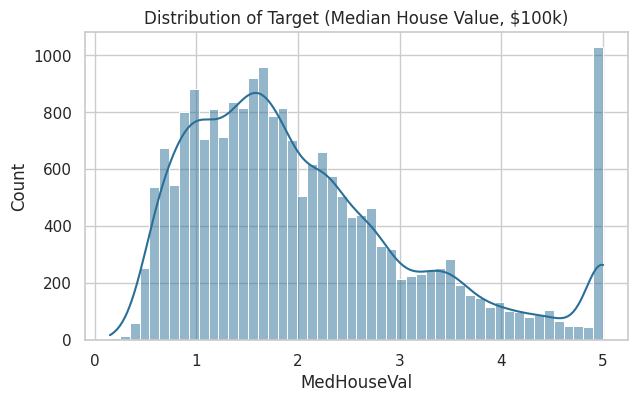

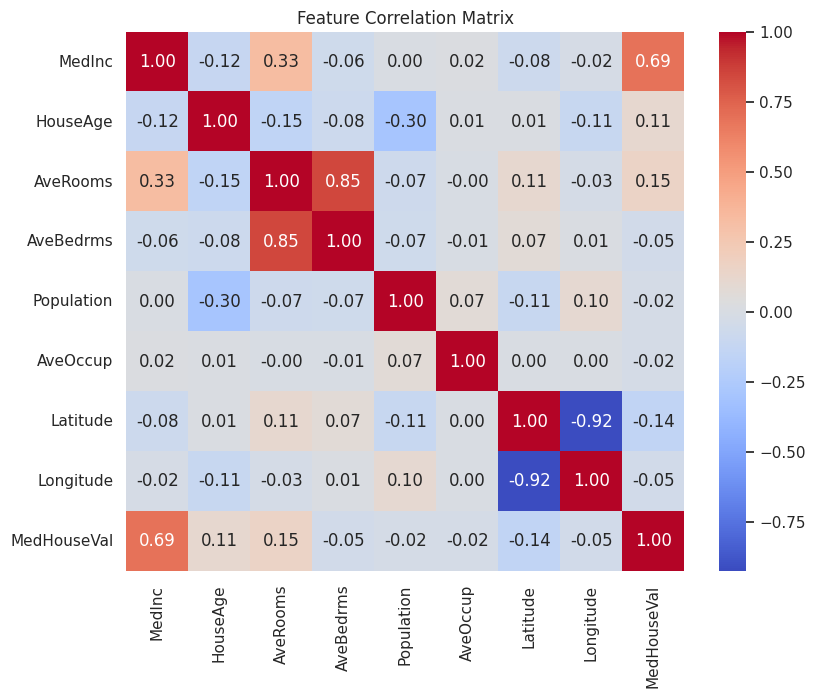

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df[target], bins=50, kde=True, color="#2a6f97", ax=ax)
ax.set_title("Distribution of Target (Median House Value, $100k)")
save_fig(fig, "01_target_distribution.png")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title("Feature Correlation Matrix")
save_fig(fig, "02_correlation_heatmap.png")

## 4. Preprocessing & Train/Test Split
Duplicates and missing values are removed (none exist here), then a single **80:20** split is made and reused by all six models.
Feature scaling is handled inside each model's Pipeline so it is learned from training data only (no data leakage).

In [5]:
df = df.drop_duplicates().dropna().reset_index(drop=True)
X, y = df[features], df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
print(f"Train size: {len(X_train)} (80%)  |  Test size: {len(X_test)} (20%)")

Train size: 16512 (80%)  |  Test size: 4128 (20%)


## 5. Model Definitions
Each model comes with a hyperparameter grid for cross-validated tuning.
Scale-sensitive models (Linear, KNN, Neural Network) use `StandardScaler`; tree-based models are scale-invariant so no scaling is applied to them.

In [6]:
models = {
    "Linear Regression": (
        Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
        {}, True),

    "Decision Tree": (
        DecisionTreeRegressor(random_state=RANDOM_STATE),
        {"max_depth": [4, 6, 8, 10, 12], "min_samples_leaf": [1, 5, 10, 20]}, False),

    "Random Forest": (
        RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
        {"n_estimators": [200], "max_depth": [12, 20, None], "min_samples_leaf": [1, 3]}, False),

    "Neural Network": (
        Pipeline([("scaler", StandardScaler()),
                  ("model", MLPRegressor(max_iter=500, early_stopping=True,
                                         validation_fraction=0.1, n_iter_no_change=15,
                                         random_state=RANDOM_STATE))]),
        {"model__hidden_layer_sizes": [(64, 32), (128, 64)],
         "model__alpha": [1e-4, 1e-2],
         "model__learning_rate_init": [1e-3]}, True),

    "XGBoost": (
        XGBRegressor(objective="reg:squarederror", random_state=RANDOM_STATE,
                     n_jobs=-1, tree_method="hist"),
        {"n_estimators": [300, 600], "max_depth": [4, 6],
         "learning_rate": [0.05, 0.1], "subsample": [0.8], "colsample_bytree": [0.8]}, False),

    "KNN": (
        Pipeline([("scaler", StandardScaler()), ("model", KNeighborsRegressor())]),
        {"model__n_neighbors": [3, 5, 7, 9, 11, 15],
         "model__weights": ["uniform", "distance"]}, True),
}
print("Models ready:", list(models))

Models ready: ['Linear Regression', 'Decision Tree', 'Random Forest', 'Neural Network', 'XGBoost', 'KNN']


## 6. Training, Tuning & Evaluation

In [ ]:
def evaluate(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "MSE": mse,
            "RMSE": float(np.sqrt(mse)),
            "R2": r2_score(y_true, y_pred)}

cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
results, predictions, fitted = [], {}, {}

for name, (estimator, grid, scaled) in models.items():
    print(f">>> Training: {name}")
    start = time.time()
    if grid:
        search = GridSearchCV(estimator, grid, cv=cv,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
        search.fit(X_train, y_train)
        best, best_params, cv_rmse = search.best_estimator_, search.best_params_, -search.best_score_
    else:
        best, best_params, cv_rmse = estimator.fit(X_train, y_train), {}, np.nan
    elapsed = time.time() - start

    y_pred = best.predict(X_test)
    m = evaluate(y_test, y_pred)
    print(f"    Best params: {best_params if best_params else 'N/A'}")
    print(f"    Test -> MAE={m['MAE']:.4f}  MSE={m['MSE']:.4f}  RMSE={m['RMSE']:.4f}  R2={m['R2']:.4f}\n")

    results.append({"Model": name, **m,
                    "Train R2": r2_score(y_train, best.predict(X_train)),
                    "CV RMSE": cv_rmse,
                    "Scaling": "Yes" if scaled else "No",
                    "Time (s)": elapsed,
                    "Best Params": str(best_params) if best_params else "-"})
    predictions[name], fitted[name] = y_pred, best

results_df = pd.DataFrame(results).set_index("Model")

>>> Training: Linear Regression
    Best params: N/A
    Test -> MAE=0.5332  MSE=0.5559  RMSE=0.7456  R2=0.5758

>>> Training: Decision Tree
    Best params: {'max_depth': 12, 'min_samples_leaf': 20}
    Test -> MAE=0.4062  MSE=0.3611  RMSE=0.6009  R2=0.7244

>>> Training: Random Forest


## 7. Comparative Performance Table (Test Set)

In [ ]:
table = results_df[["MAE", "MSE", "RMSE", "R2", "Train R2", "CV RMSE", "Time (s)"]]
results_df.to_csv(os.path.join(OUTPUT_DIR, "model_comparison.csv"))
(table.sort_values("RMSE")
      .style.format("{:.4f}")
      .background_gradient(cmap="RdYlGn_r", subset=["MAE", "MSE", "RMSE"])
      .background_gradient(cmap="RdYlGn", subset=["R2"]))

In [ ]:
results_df[["Scaling", "Best Params"]]

## 8. Visualizations

### 8.1 Actual vs Predicted

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
lo, hi = float(y_test.min()), float(y_test.max())
for ax, name in zip(axes.ravel(), predictions):
    ax.scatter(y_test, predictions[name], s=8, alpha=0.35, color="#2a6f97")
    ax.plot([lo, hi], [lo, hi], "r--", lw=1.5, label="Perfect prediction")
    ax.set_title(f"{name}\nR² = {results_df.loc[name, 'R2']:.3f} | RMSE = {results_df.loc[name, 'RMSE']:.3f}")
    ax.set_xlabel("Actual Value ($100k)"); ax.set_ylabel("Predicted Value ($100k)")
    ax.legend(loc="upper left")
fig.suptitle("Actual vs Predicted House Prices (Test Set)", fontsize=16, y=1.01)
fig.tight_layout()
save_fig(fig, "03_actual_vs_predicted.png")

### 8.2 Metric Comparison

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
palette = sns.color_palette("viridis", len(results_df))
for ax, metric in zip(axes, ["MAE", "MSE", "RMSE", "R2"]):
    vals = results_df[metric]
    bars = ax.bar(vals.index, vals.values, color=palette)
    ax.set_title(metric + ("  (higher is better)" if metric == "R2" else "  (lower is better)"))
    ax.tick_params(axis="x", rotation=40)
    for b, v in zip(bars, vals.values):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.3f}",
                ha="center", va="bottom", fontsize=9)
fig.suptitle("Model Performance Comparison (Test Set)", fontsize=16)
fig.tight_layout()
save_fig(fig, "04_metric_comparison.png")

### 8.3 Residual Plots

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    ax.scatter(pred, y_test.values - pred, s=8, alpha=0.35, color="#e07a5f")
    ax.axhline(0, color="black", lw=1)
    ax.set_title(name); ax.set_xlabel("Predicted Value"); ax.set_ylabel("Residual (Actual - Predicted)")
fig.suptitle("Residual Plots (Test Set)", fontsize=16, y=1.01)
fig.tight_layout()
save_fig(fig, "05_residual_plots.png")

### 8.4 Feature Importance (tree-based models)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, ["Decision Tree", "Random Forest", "XGBoost"]):
    imp = pd.Series(fitted[name].feature_importances_, index=features).sort_values()
    imp.plot.barh(ax=ax, color="#3d405b")
    ax.set_title(f"{name} - Feature Importance")
fig.tight_layout()
save_fig(fig, "06_feature_importance.png")

## 9. Strengths and Limitations of Each Algorithm

In [ ]:
discussion = pd.DataFrame({
    "Linear Regression": [
        "Very fast, simple and fully interpretable (coefficients show each feature's effect); no tuning needed.",
        "Assumes a linear relationship, so it cannot capture location effects or feature interactions; sensitive to outliers and multicollinearity."],
    "Decision Tree": [
        "Captures non-linearity and interactions automatically; no scaling needed; easy to visualise and explain.",
        "A single tree is unstable and prone to overfitting; predictions are piecewise constant."],
    "Random Forest": [
        "Averaging many decorrelated trees cuts variance; robust to outliers; gives feature importances with little tuning.",
        "Slower and heavier than one tree; less interpretable; cannot extrapolate beyond the training target range."],
    "Neural Network": [
        "Can model very complex non-linear patterns and scales to large datasets once properly trained.",
        "Needs scaling and careful tuning (architecture, regularisation, learning rate); a black box; often does not beat tree ensembles on small tabular data."],
    "XGBoost": [
        "Gradient boosting corrects previous errors with built-in regularisation; usually top accuracy on tabular data.",
        "Many hyperparameters to tune; harder to explain; can overfit noisy data if not regularised."],
    "KNN": [
        "Simple, non-parametric, no assumptions about data shape; good when similar houses have similar prices.",
        "Needs scaling; slow at prediction time; degrades with irrelevant features or high dimensionality."],
}, index=["Strengths", "Limitations"]).T

from IPython.display import display, HTML
display(HTML(discussion.to_html().replace("\\n", "<br>")
             .replace("<td>", "<td style='text-align:left;vertical-align:top'>")))

## 10. Best Model & Conclusion

In [ ]:
ranked = results_df.sort_values("RMSE")
best, runner, worst = ranked.index[0], ranked.index[1], ranked.index[-1]
b = results_df.loc[best]

conclusion = (
    f"BEST-PERFORMING ALGORITHM: {best}\n\n"
    f"{best} achieved the lowest test error (MAE = {b['MAE']:.4f}, MSE = {b['MSE']:.4f}, "
    f"RMSE = {b['RMSE']:.4f}) and the highest R2 ({b['R2']:.4f}) of all six models, i.e. it explains "
    f"about {b['R2']*100:.1f}% of the variance in house prices on unseen data.\n"
    f"Runner-up: {runner} (RMSE = {results_df.loc[runner,'RMSE']:.4f}, R2 = {results_df.loc[runner,'R2']:.4f}). "
    f"Weakest: {worst} (RMSE = {results_df.loc[worst,'RMSE']:.4f}, R2 = {results_df.loc[worst,'R2']:.4f}).\n\n"
    f"Train R2 vs test R2 for {best}: {b['Train R2']:.4f} vs {b['R2']:.4f} (gap shows its degree of overfitting). "
    f"Hyperparameters were chosen by {CV_FOLDS}-fold cross-validation on the training set only, "
    f"so the test scores are an unbiased estimate of generalisation performance."
)
print(conclusion)

**Written justification (edit with your own final numbers):** Linear Regression performs worst because house prices depend non-linearly on location and income. Non-linear models (tree ensembles, boosting, neural network) capture these patterns and clearly outperform it. A single Decision Tree and KNN sit in the middle: they model non-linearity but are noisier. Ensemble methods (Random Forest, XGBoost) reduce variance and typically lead on this dataset, with XGBoost usually best thanks to boosting plus regularisation.

## 11. Download All Results (Colab)

In [ ]:
import shutil
shutil.make_archive("regression_results", "zip", OUTPUT_DIR)
try:
    from google.colab import files
    files.download("regression_results.zip")
except ImportError:
    print("Saved locally as regression_results.zip")